# Recumbent fold — Surfe

Second notebook of the recumbent-fold example. `01b_recumbent_fold_fit` fits the NF
and LDI models and saves the contacts, normals and **evaluation grid**. Here
Surfe (Hillier et al.), a 3-D radial-basis-function (GRBF) implicit
interpolator, is fitted to the same data and evaluated on exactly that grid.
The data are the synthetic fold from `01a_recumbent_fold_data`, and the fit
is scored against the true units.

Surfe has no 2-D mode, so the section is embedded in 3-D at `y = 0` with zero
`y` normal components, and everything is evaluated on that plane. The
stratigraphic *Lajaunie* method (`Surfe_API(2)`) is used: one scalar field with
one isovalue per horizon. Surfe gives an analytic gradient anywhere, so
`diagnostics` finds its critical points exactly as it does for the other
methods.

Computation and diagnostics only; the plots here are not saved. The result is
saved to `results/<DATASET>/surfe.npz`. This notebook needs `surfepy`,
numpy and pandas, but not `curlew` or `torch`.


## Setup

`surfepy` is the compiled module from `DevOps/surfe/build`. If it is already
installed in this environment the path insert is harmless.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

SURFE_BUILD = Path("../../../../surfe/build").resolve()
if SURFE_BUILD.exists() and str(SURFE_BUILD) not in sys.path:
    sys.path.insert(0, str(SURFE_BUILD))
import surfepy

sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, diagnostics, exploded3d
import figstyle
import diagnostics
figstyle.apply()

import recumbent_inputs  # data loading and grid shared with 01b_recumbent_fold_fit

DATASET = "synthetic"
DATA_DIR = Path("./data")
OUT_DIR = Path("./results") / DATASET   # where 01 saves inputs.npz and this notebook saves surfe.npz
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("surfepy", surfepy.__file__)


surfepy /Users/kamath92/Documents/Work/2026/DevOps/surfe/build/surfepy.cpython-315-darwin.so


## Inputs

The contacts, bedding normals and evaluation grid. If `01b_recumbent_fold_fit`
has been run for this `DATASET`, they are read from its
`results/<DATASET>/inputs.npz`. Otherwise they are built from the CSVs in
`data/` (`data/synthetic/` for the synthetic fold) with the same loader and
grid `01` uses (`recumbent_inputs`), so the result is identical and Surfe can
run first. With synthetic data the true units on the grid come along too.

read results/synthetic/inputs.npz
horizons [8, 6], orientations 8, grid 240 x 240, origin [486.36363636 470.97912245]


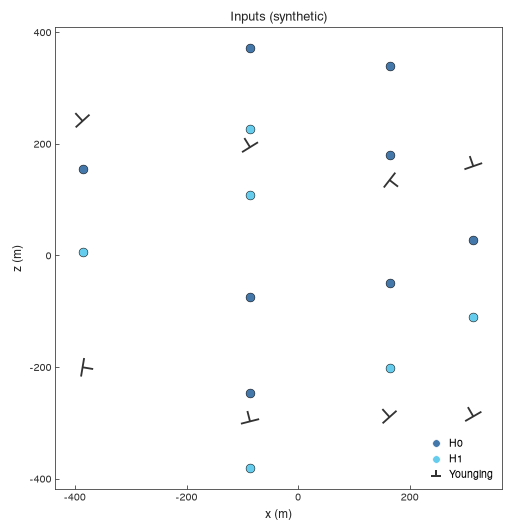

In [2]:
inputs_npz = OUT_DIR / "inputs.npz"
if inputs_npz.exists():
    inp = np.load(inputs_npz)
    horizon_names = [str(n) for n in inp["horizon_names"]]
    horizons = [inp[f"horizon_{i}"] for i in range(len(horizon_names))]
    gp, gv, origin = inp["gp"], inp["gv"], inp["origin"]
    x, z = inp["x"], inp["z"]
    source = inputs_npz
else:
    section = recumbent_inputs.load_section(DATASET, DATA_DIR)
    horizon_names, horizons = section["horizon_names"], section["horizons"]
    gp, gv, origin = section["gp"], section["gv"], section["origin"]
    x, z = recumbent_inputs.grid_axes()
    source = f"{section['sp_csv']} / {section['ori_csv']} (01 not run for '{DATASET}' yet)"
unit_true = recumbent_inputs.true_units(x, z, origin, DATA_DIR) if DATASET == "synthetic" else None
print(f"read {source}")
print(f"horizons {[len(h) for h in horizons]}, orientations {len(gp)}, grid {len(x)} x {len(z)}, origin {origin}")

fig, ax = plt.subplots(figsize=(5, 5))
figstyle.overlay_constraints(
    ax, horizons, horizon_names, gp, gv,
    colors={n: figstyle.HORIZON_PALETTE[i] for i, n in enumerate(horizon_names)},
    scatter_s=28, quiver_scale=0.025, legend=True,
)
figstyle.format_section_ax(ax, title=f"Inputs ({DATASET})")
plt.show()

## Fit

Each horizon's contacts are equality constraints: the Lajaunie method pairs the
first contact of each horizon with every other contact on it and asks the field
to take the same value at both (increments, Lajaunie et al. 1997). The *level*
passed with each contact only says which horizon it belongs to; it is never a
target value, so the isovalues are free, as for the `eq` constraints of NF and
LDI. The order of the horizons comes from the bedding normals, which point
toward younger rock.
The cubic kernel (`"r3"`) is Surfe's default for 3-D structural interpolation,
with a first-order polynomial drift.

In [3]:
# Knobs for this fit
LEVELS = {"H0": 200.0, "H1": 0.0}   # horizon labels only: Lajaunie uses equalities within each
KERNEL = "r3"                        # also: "WendlandC2", "Gaussian", "MaternC4", ...
POLY_ORDER = 1
Y_SECTION = 0.0                      # y of the plane the section is embedded on

# How strictly the data are honoured:
#   "exact"      interpolate every constraint exactly (Surfe's default)
#   "smoothing"  SetRegressionSmoothing: Surfe *overwrites* the diagonal of the contact-increment
#                block with the kernel at distance SMOOTHING (SMOOTHING**3 for "r3"; the exact
#                diagonal is -2 r**3, r the distance between paired contacts). Bedding rows are
#                not touched. Approximate fit, but not an additive nugget.
#   "restricted" SetRestrictedRange: every contact increment within +-INTERFACE_UNCERTAINTY (field
#                units, ~m here since the normals fix |grad| ~ 1) and every normal within
#                ANGULAR_UNCERTAINTY degrees of strike (half that on dip); the smoothest field
#                inside those bounds, by quadratic programming. Hard error bars on both data
#                types, the closest Surfe has to GemPy's two nuggets. Turns off the polynomial
#                drift; Surfe supports it with the cubic kernel only.
FIT_MODE = "exact"                   # "exact" | "smoothing" | "restricted"
SMOOTHING = 1.0                     # m, for "smoothing"
INTERFACE_UNCERTAINTY = 5.0          # field units (~m), for "restricted"
ANGULAR_UNCERTAINTY = 5.0            # degrees, for "restricted"

model = surfepy.Surfe_API(2)         # 2 = Lajaunie / stratigraphic scalar field

for h, name in zip(horizons, horizon_names):
    for px, pz in h:
        model.AddInterfaceConstraint(px, Y_SECTION, pz, LEVELS[name])
for (px, pz), (nx, nz) in zip(gp, gv):
    model.AddPlanarConstraintwNormal(px, Y_SECTION, pz, nx, 0.0, nz)

model.SetRBFKernel(KERNEL)
model.SetPolynomialOrder(POLY_ORDER)
# Surfe switches each option on whatever its flag says, so call only the one wanted.
if FIT_MODE == "smoothing":
    model.SetRegressionSmoothing(True, SMOOTHING)
elif FIT_MODE == "restricted":
    model.SetRestrictedRange(True, INTERFACE_UNCERTAINTY, ANGULAR_UNCERTAINTY)
elif FIT_MODE != "exact":
    raise ValueError(f"FIT_MODE must be 'exact', 'smoothing' or 'restricted', got {FIT_MODE!r}")
print("Surfe fit:", FIT_MODE)

with diagnostics.quiet():   # Surfe prints progress from C++
    model.ComputeInterpolant()

Surfe fit: exact


## Evaluate on the saved grid

Scalar and analytic gradient on the full grid. Each horizon's isovalue is the
mean of the field at its contacts, evaluated exactly, as curlew sets it for NF and LDI; lithology is the field classified
between the isovalues.

In [4]:
scalar, gradient = diagnostics.evaluate_surfe(model, x, z, y=Y_SECTION)

isovalues = diagnostics.surfe_isovalues(model, horizons, y=Y_SECTION)
litho = diagnostics.lithology_from_isovalues(scalar, isovalues)

for h, name, iso in zip(horizons, horizon_names, isovalues):
    v = diagnostics.surfe_scalar(model, h, y=Y_SECTION)
    print(f"{name}: isovalue {iso:.2f}, contact residual max {np.abs(v - iso).max():.2e}")

# Bedding normals against the field gradient (cosine; 1 = parallel)
g = diagnostics.make_surfe_gradient_function(model, y=Y_SECTION)(gp)
cos = (g * gv).sum(axis=1) / np.linalg.norm(g, axis=1)
print("gradient . normal:", np.round(cos, 3))

H0: isovalue 43.89, contact residual max 1.97e-12
H1: isovalue -56.09, contact residual max 2.24e-12
gradient . normal: [1. 1. 1. 1. 1. 1. 1. 1.]


## Critical points

`find_critical_points` only needs a gradient callable, and Surfe provides one.
Roots are refined with Newton steps against the analytic gradient, not read
off the raster.

In [5]:
critical = diagnostics.surfe_critical_points(model, x, z, y=Y_SECTION, gradient_grid=gradient)
print(f"Surfe gradient extrema: maxima={critical.counts['maximum']}, "
      f"minima={critical.counts['minimum']}, saddles={critical.counts['saddle']}")

Surfe gradient extrema: maxima=1, minima=1, saddles=2


In [6]:
# Agreement with the true units (synthetic data only), scored as in 01: lithology IDs are
# flipped if they run against the truth, then the share of grid cells in the true unit.
agreement = None
if unit_true is not None:
    n_units = len(horizons) + 1
    unit = litho if np.corrcoef(litho.ravel(), unit_true.ravel())[0, 1] >= 0 else n_units + 1 - litho
    agreement = dict(volume=float(np.mean(unit == unit_true)),
                     per_unit=[float(np.mean(unit[unit_true == u] == u)) for u in range(1, n_units + 1)])
    print(f"Surfe agreement with the true units: {100 * agreement['volume']:.1f}%; per true unit "
          + ", ".join(f"{u}: {100 * a:.1f}%" for u, a in enumerate(agreement["per_unit"], start=1)))

# The geometry where the data can decide it (recumbent_inputs.score_against_truth): the median
# distance between Surfe's contacts and the true ones within the drillholes' window, and the
# intersection over union of each unit there.
score = None
if unit_true is not None:
    reference = recumbent_inputs.truth_reference(origin, DATA_DIR)
    score = recumbent_inputs.score_against_truth(recumbent_inputs.match_units(litho, unit_true), x, z,
                                                 unit_true, reference)
    print(f"contact distance in x {np.round(reference['window'])} "
          + ", ".join(f"{n} {dist:.1f} m" for n, dist in zip(horizon_names, score["contact_distance"]))
          + "; IoU per unit " + ", ".join(f"{v:.2f}" for v in score["iou"]))

Surfe agreement with the true units: 89.9%; per true unit 1: 90.3%, 2: 85.4%, 3: 92.3%
contact distance in x [-503.  430.] H0 13.0 m, H1 9.7 m; IoU per unit 0.84, 0.71, 0.91


## Visual check

Not saved; the publication version is made in
`01e_recumbent_fold_figures.ipynb`.

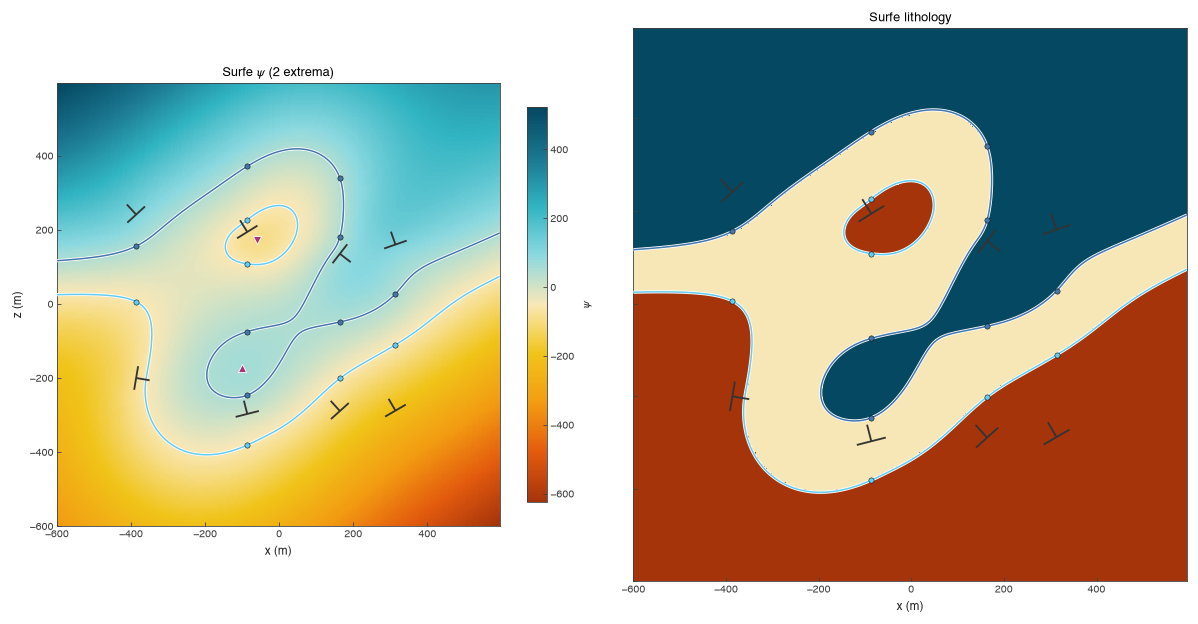

In [7]:
colors = {n: figstyle.HORIZON_PALETTE[i] for i, n in enumerate(horizon_names)}
cmap_litho, norm_litho = figstyle.litho_cmap(np.unique(litho))
extent = (x[0], x[-1], z[0], z[-1])

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
ax = axes[0]
im = ax.imshow(scalar.T, origin="lower", extent=extent, cmap=figstyle.ramp(), interpolation="nearest")
figstyle.draw_contact_contours(ax, x, z, scalar, horizons, horizon_names, colors=colors, levels=isovalues)
diagnostics.overlay_critical_points(ax, critical, size=24)
ax.set_title(diagnostics.extrema_title("Surfe", critical))
fig.colorbar(im, ax=ax, shrink=0.7, label=r"$\psi$")

ax = axes[1]
ax.imshow(litho.T, origin="lower", extent=extent, cmap=cmap_litho, norm=norm_litho, interpolation="nearest")
figstyle.draw_contact_contours(ax, x, z, scalar, horizons, horizon_names, colors=colors, levels=isovalues)
ax.set_title("Surfe lithology")

for ax in axes:
    figstyle.overlay_constraints(ax, horizons, horizon_names, gp, gv, colors=colors,
                                 scatter_s=10, quiver_scale=0.013)
    ax.set(aspect="equal", xlabel="x (m)")
axes[0].set_ylabel("z (m)")
fig.tight_layout()
plt.show()

## Save

The scalar, lithology and critical points on the shared grid, plus the settings
needed to refit the interpolant from `inputs.npz` in a few seconds (Surfe models
cannot be pickled).

In [8]:
np.savez_compressed(
    OUT_DIR / "surfe.npz",
    scalar=scalar.astype(np.float32),
    lithology=litho.astype(np.int8),
    isovalues=np.asarray(isovalues),
    kernel=KERNEL, poly_order=POLY_ORDER, y_section=Y_SECTION,
    fit_mode=FIT_MODE, smoothing=SMOOTHING,
    interface_uncertainty=INTERFACE_UNCERTAINTY, angular_uncertainty=ANGULAR_UNCERTAINTY,
    levels=np.asarray([LEVELS[n] for n in horizon_names]),
    **({"agreement": agreement["volume"], "agreement_per_unit": np.asarray(agreement["per_unit"])}
       if agreement is not None else {}),
    **({"contact_distance": np.asarray(score["contact_distance"]),
        "iou": np.asarray(score["iou"])} if score is not None else {}),
    **diagnostics.pack_critical(critical),
)
print("wrote", OUT_DIR / "surfe.npz")

wrote results/synthetic/surfe.npz
